# Nivel 3: Base + Cuestionario frente a Base

¿Cuánto mejora la predicción si el usuario responde el cuestionario de hábitos?, y ¿qué modelo lo aprovecha mejor?

| Modelo | Variables | Papel |
|---|---|---|
| Cox de Base | Base (19) | Listón a superar: es el modelo del nivel 1 |
| Cox | Base + Cuestionario (26) | Compite |
| Cox elastic net | Base + Cuestionario (26) | Compite |
| Random survival forest | Base + Cuestionario (26) | Compite |
| Gradient boosting (XGBoost) | Base + Cuestionario (26) | Compite |

Listones fijados antes de ver los resultados:

- **Hábitos con signo contrario al conocido:** no entran en el producto aunque suban el C-index. El resultado dice cuántos años suman o restan los hábitos, y un "beber te quita años" sería engañoso. Los signos esperados están en la sección 2.
- **Quitar una pregunta:** vale si baja como mucho **0,002** el C-index misma edad.
- **Cox o XGBoost:** se queda Cox salvo que XGBoost optimizado gane al menos **0,02** en C-index misma edad.
- **Quedarse con el nivel 3:** el intervalo del bootstrap frente al Cox de Base no incluye el 0 y sobreviven varias preguntas.

Primero con valores fijos y, después, optimizando solo XGBoost. Sin pesos muestrales. Todo con validación cruzada dentro de train: **el test no se toca**.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: **cerca de una hora**.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd
from lifelines import CoxPHFitter

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASE
from src.config.paths import GOLD_TABLE
from src.config.study import COMPARISON_SEED
from src.models.s1_split import cv_folds, split_data
from src.models.s2_preprocessing import build_preprocessor
from src.models.s5_evaluation import compare_risks, evaluate_level, plot_calibration, tune_model

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto que en los niveles anteriores: 80/20 con 5 bloques dentro de train.

In [2]:
# Questionnaire at the start of this notebook; its final version is QUESTIONNAIRE in model_sets.py
INITIAL_QUESTIONNAIRE = [
    "smoking", "alcohol_frequency", "alcohol_drinks", "physical_activity",
    "sedentary_hours", "fast_food_meals", "sleep_hours",
]
LEVEL_3 = BASE + INITIAL_QUESTIONNAIRE

gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Signos esperados

Qué se sabe de cada hábito, escrito antes de ver los resultados. `above`: suma riesgo (hazard ratio por encima de 1); `below`: lo resta. En las preguntas de botón, cada respuesta se compara con la de referencia: no haber fumado nunca, no beber nunca y ser sedentario.

| Hábito | Esperado |
|---|---|
| Exfumador y fumador actual | Suman frente a no haber fumado nunca |
| Beber, con cualquier frecuencia | Suma frente a no beber nunca |
| Más bebidas por día | Suman |
| Actividad moderada o intensa | Restan frente a ser sedentario |
| Más horas sentado | Suman |
| Más comidas de comida rápida | Suman |
| Horas de sueño | En U: dormir poco y mucho suman, así que el término al cuadrado suma |

Un hábito tiene **signo contrario** si alguna de sus columnas tiene un efecto claro (intervalo del 95 % que no incluye el 1) en el sentido opuesto al esperado.

El alcohol se juzga como un único hábito: si una de sus dos preguntas tiene signo contrario, salen las dos. Las bebidas por día solo se preguntan si la frecuencia no es "nunca", así que sin la frecuencia quien nunca bebe queda con 0 bebidas, mezclado con quien lo dejó por estar enfermo. *Añadido tras la primera ejecución: al quitar solo la frecuencia, las bebidas por día pasaban a salir protectoras.*

In [3]:
# Expected direction of each questionnaire column: above = adds risk, below = lowers it
EXPECTED_SIGNS = {
    "smoking_former":                     "above",
    "smoking_current":                    "above",
    "alcohol_frequency_less_than_weekly": "above",
    "alcohol_frequency_weekly":           "above",
    "alcohol_frequency_daily":            "above",
    "alcohol_drinks":                     "above",
    "physical_activity_moderate":         "below",
    "physical_activity_intense":          "below",
    "sedentary_hours":                    "above",
    "fast_food_meals":                    "above",
    "sleep_hours_squared":                "above",
}

# Questions judged as one habit
HABITS = {"alcohol_frequency": "alcohol", "alcohol_drinks": "alcohol"}

## 3. Cobertura del cuestionario

Porcentaje de personas de train con respuesta real, en total y por ciclo. El resto se rellena con la respuesta más frecuente (o la mediana) de su sexo y grupo de edad. Huecos conocidos: alcohol sin los de 18-19 años en 1999-2010 y actividad física con un cambio de cuestionario en 2007.

In [4]:
has_value = train[INITIAL_QUESTIONNAIRE].notna()
coverage = has_value.mean()

coverage_table = has_value.groupby(train["cycle"], observed=True).mean().T
coverage_table.insert(0, "total", coverage)
(coverage_table * 100).round(0).astype(int).sort_values("total")

cycle,total,1999_2000,2001_2002,2003_2004,2005_2006,2007_2008,2009_2010,2011_2012,2013_2014,2015_2016,2017_2018
fast_food_meals,50,0,0,0,0,79,77,77,77,78,79
sedentary_hours,64,0,0,0,0,100,100,100,100,99,99
sleep_hours,73,0,0,0,100,100,100,100,100,99,99
alcohol_frequency,87,83,83,82,83,89,85,90,92,91,94
alcohol_drinks,87,83,83,82,83,89,85,90,92,91,94
smoking,99,99,99,99,99,99,100,100,100,100,100
physical_activity,100,100,100,100,100,100,100,100,100,100,100


## 4. Entrenar y evaluar

Cada persona se evalúa con un modelo entrenado sin ella. Casi todo el tiempo se va en el random survival forest.

In [5]:
reference_summary, reference_details = evaluate_level(BASE, train, folds, models=["cox"])
level_summary, level_details = evaluate_level(LEVEL_3, train, folds)

## 5. Resumen

| Columna | Qué mide | Mejor |
|---|---|---|
| `c_index` | De dos personas, cuántas veces da más riesgo a la que muere antes en 10 años | Alto |
| `c_index_std` | Cuánto varía entre los 5 bloques | Bajo |
| `c_index_fit` | Lo mismo con personas ya vistas; muy por encima de `c_index` = sobreajuste | Cerca de `c_index` |
| `c_index_same_age` | Lo mismo, dentro de cada grupo de edad: **lo que más importa para el producto** | Alto |
| `c_index_female`, `c_index_male` | Lo mismo, por sexo | Altos y parecidos |
| `calibration_gap` | Diferencia media entre el riesgo previsto y el observado | Bajo |
| `worst_underestimate` | Grupo donde más se queda corto el riesgo previsto; es el error peor | Bajo |
| `seconds_per_fit` | Tiempo de un entrenamiento | Bajo |

In [6]:
pd.concat([reference_summary.rename(index={"cox": "cox_base"}), level_summary])

,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
cox_base,0.8476,0.0064,0.8480,0.7034,0.8513,0.8400,0.0042,0.0139,5.3616
cox,0.8568,0.0056,0.8576,0.7288,0.8629,0.8480,0.0052,0.0145,6.4890
elastic_net,0.8561,0.0055,0.8568,0.7281,0.8621,0.8474,0.0065,0.0239,1.2207
random_forest,0.8528,0.0043,0.9340,0.7159,0.8573,0.8449,0.0162,0.0737,53.8836
gradient_boosting,0.8579,0.0050,0.8747,0.7283,0.8633,0.8490,0.0036,0.0054,2.0437


## 6. Por grupo de edad

¿Distingue a personas de la misma edad en todos los grupos? Los grupos con pocas muertes son menos fiables.

In [7]:
by_age = pd.DataFrame({name: detail["by_age"]["c_index"] for name, detail in level_details.items()})
by_age.insert(0, "cox_base", reference_details["cox"]["by_age"]["c_index"])
by_age["deaths"] = reference_details["cox"]["by_age"]["deaths"].astype(int)
by_age.round(3)

,cox_base,cox,elastic_net,random_forest,gradient_boosting,deaths
18-29,0.682,0.688,0.682,0.691,0.698,81
30-39,0.714,0.724,0.727,0.700,0.739,89
40-49,0.704,0.748,0.744,0.742,0.749,217
50-59,0.735,0.763,0.762,0.748,0.760,388
60-69,0.720,0.749,0.749,0.738,0.749,828
70-79,0.683,0.705,0.704,0.689,0.702,1246


## 7. Calibración

Una gráfica por modelo. Sobre la diagonal, el riesgo previsto coincide con el observado; por encima de ella, el modelo se queda corto.

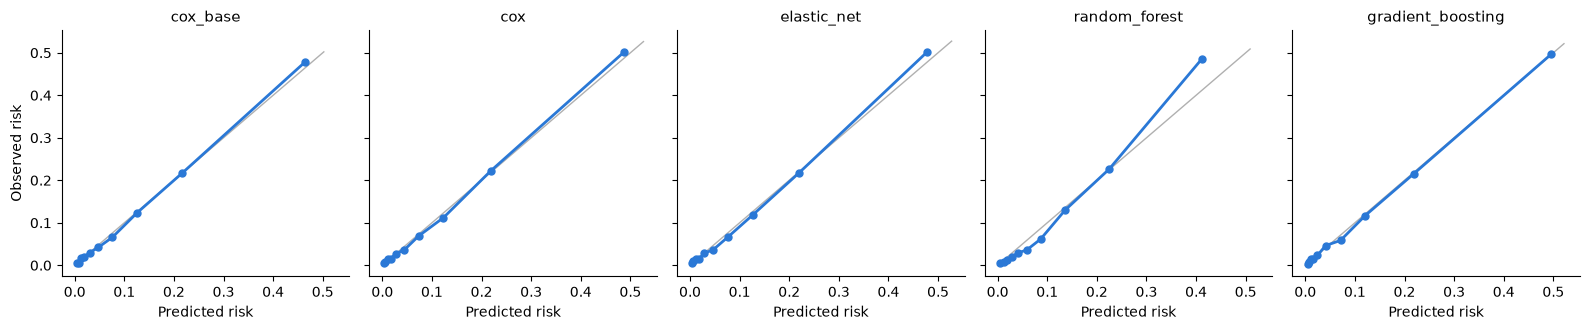

In [8]:
plot_calibration({"cox_base": reference_details["cox"], **level_details});

In [9]:
pd.DataFrame({name: detail["calibration"]["gap"] for name, detail in level_details.items()}).round(3)

,cox,elastic_net,random_forest,gradient_boosting
0,0.002,0.002,0.002,-0.002
1,0.002,0.002,-0.004,-0.001
2,0.004,0.003,-0.007,0.004
3,-0.002,-0.004,-0.009,-0.002
4,0.000,-0.000,-0.012,-0.001
5,-0.008,-0.010,-0.023,0.005
6,-0.004,-0.010,-0.025,-0.012
7,-0.011,-0.008,-0.006,-0.004
8,0.004,-0.002,0.002,-0.003
9,0.015,0.024,0.074,0.001


## 8. Optimizar XGBoost

50 intentos, buscando el mejor C-index misma edad en los mismos bloques de antes.

In [10]:
tuned = {"gradient_boosting": tune_model("gradient_boosting", LEVEL_3, train, folds)}
tuned

{'gradient_boosting': {'n_estimators': 449,
  'learning_rate': 0.027542872320280177,
  'max_depth': 5,
  'min_child_weight': 19,
  'subsample': 0.5463478857480337,
  'colsample_bytree': 0.725373101518031,
  'reg_lambda': 2.449062621475824}}

## 9. Comparar Cox y XGBoost optimizado

Con bloques nuevos, para que la optimización no infle el resultado. `xgboost_advantage` es lo que gana XGBoost en C-index misma edad; el listón es **0,02**.

In [11]:
comparison_folds = cv_folds(train, seed=COMPARISON_SEED)
tuned_summary, tuned_details = evaluate_level(LEVEL_3, train, comparison_folds, models=["cox", "gradient_boosting"], settings=tuned)
xgboost_advantage = tuned_summary.loc["gradient_boosting", "c_index_same_age"] - tuned_summary.loc["cox", "c_index_same_age"]
print(f"xgboost_advantage: {xgboost_advantage:.4f}")
tuned_summary

xgboost_advantage: 0.0056


,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
cox,0.8565,0.0034,0.8576,0.7279,0.8626,0.8475,0.0051,0.0136,4.9891
gradient_boosting,0.8610,0.0028,0.8891,0.7335,0.8659,0.8522,0.0051,0.0052,4.9525


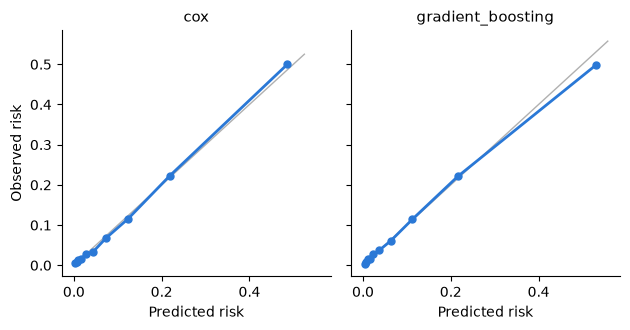

In [12]:
plot_calibration(tuned_details);

## 10. Peso de cada variable en Cox y signos

Cox simple ajustado con todo train, sin validación: describe el modelo, no mide su acierto.

- **`hazard_ratio`:** por cuánto se multiplica el riesgo al subir la variable una desviación estándar (o al dar esa respuesta frente a la de referencia), a igualdad de las demás. Por encima de 1, suma riesgo; por debajo, resta.
- **`low`, `high`:** su intervalo de confianza del 95 %. Si incluye el 1, el efecto no se distingue de cero (`clear` = False).
- **`variable`:** la pregunta o variable de la que sale cada columna.
- **`expected`, `contrary`:** signo esperado y si el efecto es claro en el sentido opuesto, solo en el cuestionario.

In [13]:
def variable_of(column):
    return next(variable for variable in sorted(LEVEL_3, key=len, reverse=True) if column == variable or column.startswith(variable + "_"))

def cox_weights(columns):
    features = build_preprocessor(columns).fit_transform(train)
    fitted = CoxPHFitter().fit(features.join(train[["follow_up_months", "death"]]), "follow_up_months", "death").summary
    weights = pd.DataFrame({
        "hazard_ratio": fitted["exp(coef)"],
        "low": fitted["exp(coef) lower 95%"],
        "high": fitted["exp(coef) upper 95%"],
        "p": fitted["p"],
    })
    weights["clear"] = (weights["low"] > 1) | (weights["high"] < 1)
    weights["variable"] = [variable_of(column) for column in weights.index]
    weights["expected"] = pd.Series(EXPECTED_SIGNS).reindex(weights.index)
    weights["contrary"] = ((weights["expected"] == "above") & (weights["high"] < 1)) | ((weights["expected"] == "below") & (weights["low"] > 1))
    return weights

weights = cox_weights(LEVEL_3)
weights.sort_values("p").round(3)

,hazard_ratio,low,high,p,clear,variable,expected,contrary
covariate,,,,,,,,
age,3.399,3.217,3.592,0.000,True,age,NaN,False
smoking_current,2.087,1.914,2.275,0.000,True,smoking,above,False
rdw,1.249,1.211,1.289,0.000,True,rdw,NaN,False
glucose,1.156,1.127,1.186,0.000,True,glucose,NaN,False
ast,1.285,1.226,1.346,0.000,True,ast,NaN,False
erythrocytes,0.731,0.688,0.776,0.000,True,erythrocytes,NaN,False
alt,0.775,0.732,0.820,0.000,True,alt,NaN,False
lymphocytes,0.875,0.847,0.904,0.000,True,lymphocytes,NaN,False
alcohol_frequency_weekly,0.558,0.482,0.646,0.000,True,alcohol_frequency,above,True


In [14]:
def habit_of(question):
    return HABITS.get(question, question)

contrary_habits = {habit_of(variable) for variable in INITIAL_QUESTIONNAIRE if weights.loc[weights["variable"] == variable, "contrary"].any()}
contrary = [variable for variable in INITIAL_QUESTIONNAIRE if habit_of(variable) in contrary_habits]
unclear = [variable for variable in INITIAL_QUESTIONNAIRE if variable not in contrary and not weights.loc[weights["variable"] == variable, "clear"].any()]
print("Habits against the expected sign:", contrary)
print("Habits without a clear effect:", unclear)
weights[weights["variable"].isin(INITIAL_QUESTIONNAIRE)].round(3)

Habits against the expected sign: ['alcohol_frequency', 'alcohol_drinks']
Habits without a clear effect: ['fast_food_meals']


,hazard_ratio,low,high,p,clear,variable,expected,contrary
covariate,,,,,,,,
alcohol_drinks,1.109,1.040,1.182,0.002,True,alcohol_drinks,above,False
sedentary_hours,1.087,1.048,1.128,0.000,True,sedentary_hours,above,False
fast_food_meals,1.002,0.959,1.047,0.933,False,fast_food_meals,above,False
sleep_hours,1.010,0.978,1.043,0.541,False,sleep_hours,NaN,False
smoking_former,1.271,1.182,1.368,0.000,True,smoking,above,False
smoking_current,2.087,1.914,2.275,0.000,True,smoking,above,False
alcohol_frequency_less_than_weekly,0.628,0.556,0.708,0.000,True,alcohol_frequency,above,True
alcohol_frequency_weekly,0.558,0.482,0.646,0.000,True,alcohol_frequency,above,True
alcohol_frequency_daily,0.594,0.504,0.699,0.000,True,alcohol_frequency,above,True


## 11. Variantes

Mismo Cox y mismos bloques, cambiando solo las variables. Solo se pueden quitar preguntas del cuestionario: Base ya se decidió en el nivel 1. Los hábitos con signo contrario salen siempre. Quitar además los que no tienen efecto claro vale si baja como mucho **0,002** el C-index misma edad frente a `no_contrary`.

| Variante | Qué cambia |
|---|---|
| `base_19` | Sin cuestionario, como referencia |
| `all_26` | Base + todo el cuestionario |
| `no_contrary` | Quita los hábitos con signo contrario (el alcohol, entero) |
| `no_contrary_unclear` | Quita, además, los hábitos sin efecto claro |

In [15]:
def without(columns, removed):
    return [column for column in columns if column not in removed]

variants = {
    "base_19": BASE,
    "all_26": LEVEL_3,
    "no_contrary": without(LEVEL_3, contrary),
    "no_contrary_unclear": without(LEVEL_3, contrary + unclear),
}
results = {name: evaluate_level(columns, train, folds, models=["cox"]) for name, columns in variants.items()}

variant_summary = pd.concat({name: summary.iloc[0] for name, (summary, _) in results.items()}, axis=1).T
variant_summary.insert(0, "variables", [len(columns) for columns in variants.values()])
variant_summary["same_age_change"] = variant_summary["c_index_same_age"] - variant_summary.loc["no_contrary", "c_index_same_age"]

final = "no_contrary_unclear" if variant_summary.loc["no_contrary_unclear", "same_age_change"] >= -0.002 else "no_contrary"
print("Final variant:", final)
variant_summary[["variables", "c_index", "c_index_same_age", "same_age_change", "calibration_gap", "worst_underestimate"]]

Final variant: no_contrary_unclear


,variables,c_index,c_index_same_age,same_age_change,calibration_gap,worst_underestimate
base_19,19,0.8476,0.7034,-0.0215,0.0042,0.0139
all_26,26,0.8568,0.7288,0.0039,0.0052,0.0145
no_contrary,24,0.8554,0.7249,0.0000,0.0053,0.0183
no_contrary_unclear,23,0.8554,0.7249,0.0000,0.0055,0.0187


## 12. Pesos del modelo final

Comprobación de que, sin los hábitos quitados, ninguno de los que quedan ha pasado a tener signo contrario.

In [16]:
final_weights = cox_weights(variants[final])
print("Contrary signs left:", final_weights.index[final_weights["contrary"]].tolist())
final_weights.sort_values("p").round(3)

Contrary signs left: []


,hazard_ratio,low,high,p,clear,variable,expected,contrary
covariate,,,,,,,,
age,3.514,3.341,3.696,0.000,True,age,NaN,False
smoking_current,2.015,1.851,2.193,0.000,True,smoking,above,False
rdw,1.250,1.211,1.289,0.000,True,rdw,NaN,False
glucose,1.165,1.135,1.195,0.000,True,glucose,NaN,False
ast,1.295,1.235,1.358,0.000,True,ast,NaN,False
erythrocytes,0.739,0.696,0.785,0.000,True,erythrocytes,NaN,False
alt,0.765,0.722,0.809,0.000,True,alt,NaN,False
physical_activity_intense,0.673,0.609,0.743,0.000,True,physical_activity,below,False
lymphocytes,0.881,0.853,0.909,0.000,True,lymphocytes,NaN,False


## 13. ¿El cuestionario aporta de verdad?

Comparación con bootstrap del modelo final frente al Cox de Base, de unos 22 minutos. Va al final para medir solo lo que el producto va a usar: sin los hábitos con signo contrario. La mejora es real si el intervalo (`low`, `high`) no incluye el 0.

In [17]:
compare_risks(results[final][1]["cox"]["risk"], reference_details["cox"]["risk"], train)

,difference,low,high
c_index,0.0078,0.0062,0.0093
c_index_same_age,0.0213,0.0160,0.0261


## 14. Conclusión

**Modelo del nivel 3: Cox simple con 23 variables**, las 19 de Base y 4 hábitos: tabaco, actividad física, horas sentado y horas de sueño. Las cifras son de validación cruzada dentro de train; el test sigue sin tocar.

### Qué se hizo y por qué

**1. Mirar la cobertura del cuestionario**

Tabaco y actividad física tienen respuesta en casi todas las personas, y el alcohol, en el 87 %. Tres preguntas no existen en los primeros ciclos: el sueño empieza en 2005 (73 %), las horas sentado en 2007 (64 %) y la comida rápida en 2007, con un 77-79 % de respuesta por ciclo (50 % en total).

**2. Comparar los cuatro modelos con valores fijos y las 26 variables**

| Modelo | C-index | Misma edad | En entrenamiento |
|---|---|---|---|
| Cox de Base (nivel 1) | 0,848 | 0,703 | 0,848 |
| Cox | 0,857 | 0,729 | 0,858 |
| Elastic net | 0,856 | 0,728 | 0,857 |
| Random survival forest | 0,853 | 0,716 | 0,934 |
| XGBoost | 0,858 | 0,728 | 0,875 |

Cox, elastic net y XGBoost quedan casi empatados. El random survival forest vuelve a sobreajustar y a quedarse 7 puntos corto en el grupo de mayor riesgo.

**3. Optimizar XGBoost y compararlo con Cox, con otros bloques**

| Modelo | C-index | Misma edad | En entrenamiento | Mayor infraestimación |
|---|---|---|---|---|
| Cox simple | 0,857 | 0,728 | 0,858 | 1,4 puntos |
| XGBoost optimizado | 0,861 | 0,734 | 0,889 | 0,5 puntos |

XGBoost gana 0,006 en misma edad, lejos del listón de 0,02, y sobreajusta más. Se queda Cox.

**4. Quitar los hábitos con signo contrario: el alcohol, entero**

Beber, con cualquier frecuencia, sale con un 37-44 % menos de riesgo que no beber nunca. Es la causalidad inversa esperada: entre quienes no beben están quienes lo dejaron por estar enfermos. Al quitar solo la frecuencia, las bebidas por día pasaban a salir protectoras por lo mismo, así que el alcohol sale entero. Cuesta 0,004 de C-index misma edad (0,7288 → 0,7249), un precio asumido de antemano para no decir al usuario que beber le quita años.

**5. Quitar los hábitos que no aportan**

La comida rápida no tiene efecto claro y quitarla no cambia el C-index misma edad (0,7249). Sale.

**6. Confirmar que el cuestionario aporta de verdad**

Modelo final frente a Cox de Base, con bootstrap: **+0,008** de C-index global (intervalo del 95 %: 0,006 a 0,009) y **+0,021** en misma edad (0,016 a 0,026). La mejora es real: unas 2 parejas más de cada 100 entre personas de edad parecida.

### Resultado final

| Cox simple, 23 variables | |
|---|---|
| C-index | 0,855 |
| C-index misma edad | 0,725 |
| Diferencia media de calibración | 0,6 puntos |
| Mayor infraestimación | 1,9 puntos |

**Variables:** las 19 de Base, más tabaco, actividad física, horas sentado y horas de sueño.

**Peso de los hábitos**, a igualdad de lo demás: fumar dobla el riesgo y haber fumado lo sube un 24 %, frente a no haber fumado nunca. La actividad moderada lo baja un 25 % y la intensa, un 33 %, frente a ser sedentario. Más horas sentado y dormir lejos de lo habitual, por poco o por mucho, lo suben.

### Limitaciones

- **El alcohol no se pregunta,** aunque el usuario lo espera en un cuestionario de hábitos. Con NHANES no se puede separar a quien nunca bebió de quien lo dejó por enfermedad. La app tendrá que aclararlo.
- **Regla del alcohol añadida tras la primera ejecución:** juzgarlo como un único hábito no estaba entre los signos fijados de antemano. Se añadió al ver que las bebidas por día cambiaban de signo al quitar la frecuencia.
- **Más infraestimación en el grupo de mayor riesgo:** 1,9 puntos, frente a 1,4 del Cox de Base y 0,5 de XGBoost optimizado. Es el error peor; hay que vigilarlo al traducir el riesgo a edad, como en el nivel 2.
- **Sueño y horas sentado sin los primeros ciclos,** justo los que más muertes tienen. Su efecto puede estar diluido por el relleno, aunque sigue siendo claro.
- **Son hábitos declarados,** no medidos, y la actividad física cambió de cuestionario en 2007.
- **Sin pesos muestrales** y con población de EE. UU.; se asume equivalencia con España.
- **Falta el test,** que se mira una sola vez, al final.